{'x': 10, 'y': 5, 'result': 30}


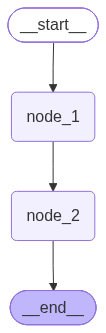

In [ ]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END
#Graph display
from IPython.display import Image, display

class State(TypedDict):
    x: int
    y: int
    result: int


def func1(state: State) -> State:
    result = state["x"] + state["y"]
    return {"result": result}


def func2(state: State) -> State:
    result = state["result"] * 2
    return {"result": result}


workflow = StateGraph(State)

workflow.add_node("node_1", func1)
workflow.add_node("node_2", func2)

workflow.add_edge(START, "node_1")
workflow.add_edge("node_1", "node_2")
workflow.add_edge("node_2", END)

app = workflow.compile()

response = app.invoke({"x": 10, "y": 5})
print(response)

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    pass

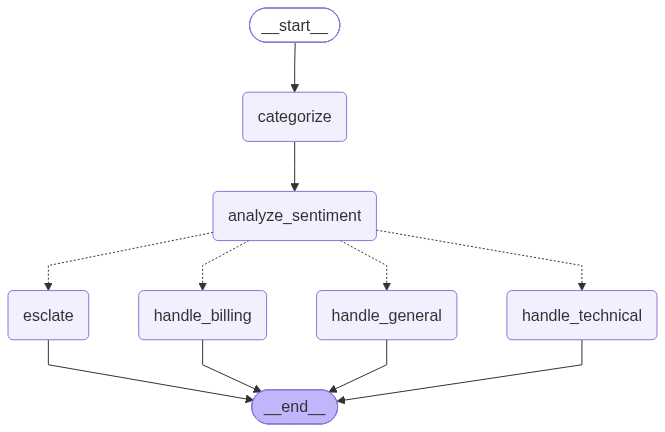

In [1]:
from typing_extensions import TypedDict, Dict
from langgraph.graph import StateGraph, END
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables.graph import MermaidDrawMethod
from IPython.display import Image, display
from langchain_nvidia_ai_endpoints import ChatNVIDIA

from dotenv import load_dotenv

load_dotenv()

llm = ChatNVIDIA(
    model="nvidia/nemotron-3-super-120b-a12b",
    temperature=0.6
)
# response = llm.invoke("what is langchain") # AIMessage response is returned
# print(response.text)
# exit
# State will be the input schema for all the nodes and edges in the graph.
# So whenever we creating nodes or edges, the state we need to pass(everything is passed as a dict)
# Define State of the Graph
class State(TypedDict):
    query: str
    category: str
    sentiment: str
    response: str

def categorize(state: State) -> State:
    prompt = ChatPromptTemplate.from_template("Categorize the following query into one of the following categories"
    "Technical, Billing, General. Query: {query}")

    #create a chain that returns category for the query
    chain = prompt | llm
    category = chain.invoke({"query": state["query"]}).content
    print(f"\nCategory: {category}")
    return {"category": category}

def analyze_sentiment(state: State) -> State:
    print("\nAnalyzing the sentiment: ")
    prompt = ChatPromptTemplate.from_template(
        "Analyze the sentiment of the following customer query and ans in one word"
        "Response with either 'Positive', 'Neutral', or 'Negative'. Query: {query}"
    )
    chain = prompt | llm
    sentiment = chain.invoke({"query": state["query"]}).content
    print(f"\nSentiment : {sentiment}")
    return {"sentiment": sentiment}

# we can some other llm to handle this
def handle_technical(state: State) -> State:
    print(f'\nHandling the technical query')
    prompt = ChatPromptTemplate.from_template(
        "Provide a technical support response to the following query: {query}"
    )
    chain = prompt | llm
    response = chain.invoke({"query": state["query"]}).content
    return {"response": response}

# we can some other llm to handle this
def handle_billing(state: State) -> State:
    print(f'\nHandling the billing query')
    prompt = ChatPromptTemplate.from_template(
        "Provide a billing support response to the following query: {query}"
    )
    chain = prompt | llm
    response = chain.invoke({"query": state["query"]}).content
    return {"response": response}

# we can some other llm to handle this
def handle_general(state: State) -> State:
    print(f'\nHandling the general query')
    prompt = ChatPromptTemplate.from_template(
        "Provide a general support response to the following query: {query}"
    )
    chain = prompt | llm
    response = chain.invoke({"query": state["query"]}).content
    return {"response": response}

# we can some other llm to handle this
def esclate(state: State) -> State:
    print(f"Esclating Query")
    return {"response": "This query has been esclate to a human agent due to its negative sentiment."}

# returning the name of the next node:
def route_query(state: State) -> str:
    if "negative" in state["sentiment"].lower():
        return "esclate"
    elif "technical" in state["category"].lower():
        return "handle_technical"
    elif "billing" in state["category"].lower():
        return "handle_billing"
    else:
        return "handle_general"

def run_customer_support(query: str) -> Dict[str, str]:
    results = app.invoke({"query": query})
    return {
        "category":results['category'],
        "sentiment":results['sentiment'],
        "response": results['response'],
    }

# Create State Graph(Workflow)
workflow = StateGraph(State)

workflow.add_node("categorize", categorize)
workflow.add_node("analyze_sentiment", analyze_sentiment)
workflow.add_node("handle_technical", handle_technical)
workflow.add_node("handle_billing", handle_billing)
workflow.add_node("handle_general", handle_general)
workflow.add_node("esclate", esclate)

workflow.add_conditional_edges(
    "analyze_sentiment",
    route_query,
    {
        "esclate": "esclate",
        "handle_technical": "handle_technical",
        "handle_billing": "handle_billing",
        "handle_general": "handle_general",
    }
)
workflow.add_edge("categorize", "analyze_sentiment")
workflow.add_edge("handle_technical", END)
workflow.add_edge("handle_billing", END)
workflow.add_edge("handle_general", END)
workflow.add_edge("esclate", END)

workflow.set_entry_point("categorize")
app = workflow.compile()
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [17]:
# Test the workflow
query = "The price value in my invoice is wrong"
query2 = "The price of the phone was cheaper and liked the service of purchasing from GAHT Market"
query3 = "I am really happy with the service and I want invoice for my new purchase."
result = run_customer_support(query2)
print(f"\n\nComputed Result:")
print(f"Query: {query2}")
print(f"\n\nCategory: {result['category']}")
print(f"\n\nSentiment: {result['sentiment']}")
print(f"\n\nResponse: {result['response']}")
print("\n")


Category: General

Analyzing the sentiment: 

Sentiment : Positive

Handling the general query


Computed Result:
Query: The price of the phone was cheaper and liked the service of purchasing from GAHT Market


Category: General


Sentiment: Positive


Response: That's fantastic to hear! It's always great when a purchase checks both boxes—great value (like that cheaper price you found) *and* a smooth, positive service experience. Hearing you liked the service at GAHT Market specifically means a lot; it’s what we aim for every time.  

If you have any other questions about your phone, need help with accessories, or are thinking about your next tech purchase, don’t hesitate to reach out. Enjoy your new device! 😊




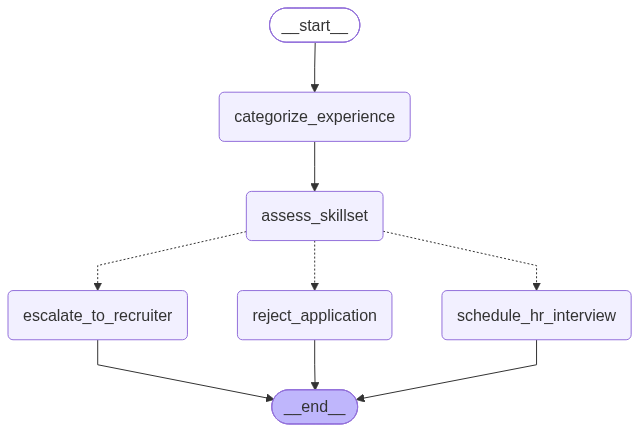

In [ ]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
from langchain_core.prompts import ChatPromptTemplate
from IPython.display import Image, display
from langchain_nvidia_ai_endpoints import ChatNVIDIA

from dotenv import load_dotenv

load_dotenv()

llm = ChatNVIDIA(
    model="nvidia/nemotron-3-super-120b-a12b",
    temperature=0.6
)

class State(TypedDict):
  application: str
  experience_level: str
  skill_match : str
  response: str
  
workflow = StateGraph(State)

def categorize_experience(state: State) -> State:
  print("\nCategorizing the experience level of candidate : ")
  prompt = ChatPromptTemplate.from_template(
      "Based on the following job application, categorize the candidate as 'Entry-level', 'Mid-level' or 'Senior-level'"
      "Application : {application}"
  )
  chain = prompt | llm
  experience_level = chain.invoke({"application": state["application"]}).content
  print(f"Experience Level : {experience_level}")
  return {"experience_level" : experience_level}

def assess_skillset(state: State) -> State:
  print("\nAssessing the skillset of candidate : ")
  prompt = ChatPromptTemplate.from_template(
      "Based on the job application for a Python Developer, assess the candidate's skillset"
      "Respond with either 'Match' or 'No Match'"
      "Application : {application}"
  )
  chain = prompt | llm
  skill_match = chain.invoke({"application": state["application"]}).content
  print(f"Skill Match : {skill_match}")
  return {"skill_match" : skill_match}

def schedule_hr_interview(state: State) -> State:
  print("\nScheduling the interview : ")
  return {"response" : "Candidate has been shortlisted for an HR interview."}

def escalate_to_recruiter(state: State) -> State:
  print("Escalating to recruiter")
  return {"response" : "Candidate has senior-level experience but doesn't match job skills."}

def reject_application(state: State) -> State:
  print("Sending rejecting email")
  return {"response" : "Candidate doesn't meet JD and has been rejected."}

workflow.add_node("categorize_experience", categorize_experience)
workflow.add_node("assess_skillset", assess_skillset)
workflow.add_node("schedule_hr_interview", schedule_hr_interview)
workflow.add_node("escalate_to_recruiter", escalate_to_recruiter)
workflow.add_node("reject_application", reject_application)

def route_app(state: State) -> str:
  if(state["skill_match"] == "Match"):
    return "schedule_hr_interview"
  elif(state["experience_level"] == "Senior-level"):
    return "escalate_to_recruiter"
  else:
    return "reject_application"


workflow.add_edge("categorize_experience", "assess_skillset")

workflow.add_conditional_edges(
    "assess_skillset",
    route_app,
    {
        "schedule_hr_interview": "schedule_hr_interview",
        "escalate_to_recruiter": "escalate_to_recruiter",
        "reject_application": "reject_application",
    }
)

workflow.add_edge(START, "categorize_experience")
workflow.add_edge("assess_skillset", END)
workflow.add_edge("escalate_to_recruiter", END)
workflow.add_edge("reject_application", END)
workflow.add_edge("schedule_hr_interview", END)

# workflow.set_entry_point("categorize_experience")
app = workflow.compile()
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception:
    pass


In [9]:
def run_candidate_screening(application: str):
  results = app.invoke({"application" : application})
  return {
      "experience_level" : results["experience_level"],
      "skill_match" : results["skill_match"],
      "response" : results["response"]
  }
  
application_text = "I have 10 years of experience in software engineering with expertise in JAVA"
results = run_candidate_screening(application_text)
print("\n\nComputed Results :")
print(f"Application: {application_text}")
print(f"Experience Level: {results['experience_level']}")
print(f"Skill Match: {results['skill_match']}")
print(f"Response: {results['response']}")


Categorizing the experience level of candidate : 
Experience Level : Senior-level

Assessing the skillset of candidate : 
Skill Match : No Match
Escalating to recruiter


Computed Results :
Application: I have 10 years of experience in software engineering with expertise in JAVA
Experience Level: Senior-level
Skill Match: No Match
Response: Candidate has senior-level experience but doesn't match job skills.


In [10]:
application_text = "I have 1 year of experience in software engineering with expertise in JAVA"
results = run_candidate_screening(application_text)
print("\n\nComputed Results :")
print(f"Application: {application_text}")
print(f"Experience Level: {results['experience_level']}")
print(f"Skill Match: {results['skill_match']}")
print(f"Response: {results['response']}")


Categorizing the experience level of candidate : 
Experience Level : Entry-level

Assessing the skillset of candidate : 
Skill Match : No Match
Sending rejecting email


Computed Results :
Application: I have 1 year of experience in software engineering with expertise in JAVA
Experience Level: Entry-level
Skill Match: No Match
Response: Candidate doesn't meet JD and has been rejected.


In [11]:
application_text = "I have experience in software engineering with expertise in Python"
results = run_candidate_screening(application_text)
print("\n\nComputed Results :")
print(f"Application: {application_text}")
print(f"Experience Level: {results['experience_level']}")
print(f"Skill Match: {results['skill_match']}")
print(f"Response: {results['response']}")


Categorizing the experience level of candidate : 
Experience Level : Entry-level

Assessing the skillset of candidate : 
Skill Match : Match

Scheduling the interview : 


Computed Results :
Application: I have experience in software engineering with expertise in Python
Experience Level: Entry-level
Skill Match: Match
Response: Candidate has been shortlisted for an HR interview.


In [12]:
application_text = "I have 5 years of experience in software engineering with expertise in C++"
results = run_candidate_screening(application_text)
print("\n\nComputed Results :")
print(f"Application: {application_text}")
print(f"Experience Level: {results['experience_level']}")
print(f"Skill Match: {results['skill_match']}")
print(f"Response: {results['response']}")


Categorizing the experience level of candidate : 
Experience Level : Mid-level

Assessing the skillset of candidate : 
Skill Match : No Match
Sending rejecting email


Computed Results :
Application: I have 5 years of experience in software engineering with expertise in C++
Experience Level: Mid-level
Skill Match: No Match
Response: Candidate doesn't meet JD and has been rejected.
